# Experiment Results Comparison

This notebook reads one or more `eval_report.json` files and builds the comparison tables and plots used to evaluate experiment results.

Paste report paths in the `REPORT_PATHS` cell below. The paths can be absolute, relative to the repository root, or relative to the current notebook working directory. Each report contains all run metadata, so grouping is derived from the JSON content rather than from folder names.

In [1]:
from __future__ import annotations

import csv
import json
import math
import textwrap
from collections import defaultdict
from pathlib import Path
from typing import Any

import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str):
        pass

    def display(value: Any) -> None:
        print(value)

sns.set_theme(context="notebook", style="whitegrid", font_scale=1.0)
pd.set_option("display.max_columns", 120)
pd.set_option("display.max_colwidth", 140)
plt.rcParams.update({
    "figure.dpi": 130,
    "savefig.dpi": 180,
    "axes.titleweight": "bold",
    "axes.titlesize": 11,
    "axes.labelsize": 10,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
})

## Data Sources

Paste or edit report paths here. Keep one path per line when using `REPORT_PATHS_TEXT`, or use a Python list in `REPORT_PATHS`.

In [2]:
REPORT_PATHS_TEXT = """
webots/controllers/crazyflie_AIF/logs/conf45_F1/eval_aif_saccade_GT_time625_f1/eval_report/eval_report.json
webots/controllers/crazyflie_AIF/logs/conf45_F1/eval_aif_saccade_mobile_time625_f1/eval_report/eval_report.json
webots/controllers/crazyflie_AIF/logs/conf45_F1/eval_aif_saccade_YOLOnano_time625_f1/eval_report/eval_report.json
webots/controllers/crazyflie_AIF/logs/conf45_F1/eval_aif_saccade_YOLOsmall_time625_f1/eval_report/eval_report.json
webots/controllers/crazyflie_AIF/logs/conf45_F1/eval_spiral_GT_time625_f1/eval_report/eval_report.json
webots/controllers/crazyflie_AIF/logs/conf45_F3/eval_spiral_GT_time625_f3/eval_report/eval_report.json
"""

REPORT_PATHS = [line.strip() for line in REPORT_PATHS_TEXT.splitlines() if line.strip() and not line.strip().startswith("#")]

SAVE_FIGURES = False
FIGURE_DIR = Path("webots/controllers/crazyflie_AIF/utils/results_comp_figures")

## Helpers

In [3]:
POLICY_LABELS = {
    "aif_saccade": "AIF saccade",
    "spiral": "Spiral",
    "wall_following": "Wall following",
    "pseudo_random": "Pseudo random",
    "rotate_and_measure": "Rotate and measure",
}

POLICY_ORDER = list(POLICY_LABELS.values())
DETECTOR_ORDER = ["GT", "YOLOn", "YOLOs", "MobileNet-SSD"]
DETECTOR_COLORS = {
    "GT": "#4C78A8",
    "YOLOn": "#F58518",
    "YOLOs": "#54A24B",
    "MobileNet-SSD": "#B279A2",
}


PROJECT_ROOT_HINTS = [
    Path("/home/ale/dev/thesis_project/aif-explo-drones"),
    Path.home() / "dev/thesis_project/aif-explo-drones",
]


def looks_like_repo_root(path: Path) -> bool:
    return (path / "webots/controllers/crazyflie_AIF").exists()


def find_repo_root(start: Path | None = None) -> Path:
    start = (start or Path.cwd()).resolve()
    candidates = [start, *start.parents, *PROJECT_ROOT_HINTS]
    for candidate in candidates:
        candidate = candidate.expanduser().resolve()
        if looks_like_repo_root(candidate):
            return candidate
    return start


REPO_ROOT = find_repo_root()
display(Markdown(f"Kernel cwd: `{Path.cwd()}`  \nDetected repo root: `{REPO_ROOT}`"))


def resolve_report_path(path_like: str | Path) -> Path:
    path = Path(path_like).expanduser()
    if path.is_absolute() and path.exists():
        return path

    candidates = [Path.cwd() / path, REPO_ROOT / path]
    if "webots" in path.parts:
        webots_index = path.parts.index("webots")
        webots_relative_path = Path(*path.parts[webots_index:])
        candidates.append(REPO_ROOT / webots_relative_path)
    for root_hint in PROJECT_ROOT_HINTS:
        candidates.append(root_hint.expanduser() / path)

    for candidate in candidates:
        if candidate.exists():
            return candidate.resolve()

    raise FileNotFoundError(f"Report not found: {path_like}")


def as_float(value: Any) -> float:
    if value is None:
        return math.nan
    try:
        return float(value)
    except (TypeError, ValueError):
        return math.nan


def is_number(value: Any) -> bool:
    value = as_float(value)
    return not math.isnan(value)


def threshold_label(threshold: Any, streak_steps: Any) -> str:
    threshold_value = as_float(threshold)
    conf = "confNA" if math.isnan(threshold_value) else f"conf{int(round(threshold_value * 100)):02d}"
    try:
        streak = f"f{int(streak_steps)}"
    except (TypeError, ValueError):
        streak = "fNA"
    return f"{conf}_{streak}"


def detector_limit_label(limitations: dict[str, Any] | None) -> str:
    if not isinstance(limitations, dict):
        return "detlimNA"

    mode = limitations.get("mode")
    if mode in (None, "none", "off"):
        return "detlim_none"
    if mode == "time":
        seconds = as_float(limitations.get("time_interval_s"))
        return "timeNA" if math.isnan(seconds) else f"time{int(round(seconds * 1000)):03d}"
    if mode == "frames":
        frames = limitations.get("frames_interval")
        return f"frames{frames if frames is not None else 'NA'}"

    parts = [str(mode)]
    for key in sorted(k for k in limitations if k != "mode"):
        value = limitations.get(key)
        if value is not None:
            parts.append(f"{key}={value}")
    return "_".join(parts)


def detector_label(report: dict[str, Any]) -> str:
    used = str(report.get("detector_used") or "unknown").lower()
    family = str(report.get("detector_model_family") or "").lower()
    size = str(report.get("detector_model_size") or "").lower()
    variant = str(report.get("detector_model_variant") or "").lower()

    if used == "ground_truth" or family == "ground_truth":
        return "GT"
    if used == "mobilenet_ssd" or "mobilenet" in family:
        return "MobileNet-SSD"
    if used == "yolo" or "yolo" in family or "yolo" in variant:
        if size in {"nano", "n"} or variant.endswith("n"):
            return "YOLOn"
        if size in {"small", "s"} or variant.endswith("s"):
            return "YOLOs"
        return f"YOLO-{size}" if size else "YOLO"
    return report.get("detector_used") or "unknown"


def policy_label(policy: Any) -> str:
    policy = str(policy or "unknown")
    return POLICY_LABELS.get(policy, policy.replace("_", " ").title())


def experiment_setup_label(report: dict[str, Any]) -> str:
    spawn = report.get("spawn_conditions") or "spawnNA"
    target = report.get("target_setup") or "targetNA"
    return f"{spawn}_{target}"


def format_mean_std(mean: Any, std: Any = math.nan, digits: int = 3, percent: bool = False) -> str:
    mean = as_float(mean)
    std = as_float(std)
    if math.isnan(mean):
        return ""

    scale = 100.0 if percent else 1.0
    suffix = "%" if percent else ""
    if math.isnan(std):
        return f"{mean * scale:.{digits}f}{suffix}"
    return f"{mean * scale:.{digits}f} ± {std * scale:.{digits}f}{suffix}"


def format_float(value: Any, digits: int = 3) -> str:
    value = as_float(value)
    return "" if math.isnan(value) else f"{value:.{digits}f}"


def format_percent(value: Any, digits: int = 2, value_is_ratio: bool = True) -> str:
    value = as_float(value)
    if math.isnan(value):
        return ""
    scale = 100.0 if value_is_ratio else 1.0
    return f"{value * scale:.{digits}f}%"


def order_index(value: str, preferred: list[str]) -> tuple[int, str]:
    return (preferred.index(value), value) if value in preferred else (len(preferred), value)


def wrap_title(text: str, width: int = 88) -> str:
    return "\n".join(textwrap.wrap(text, width=width, break_long_words=False))

Kernel cwd: `/home/ale/dev/thesis_project/aif-explo-drones/webots/controllers/crazyflie_AIF/utils`  
Detected repo root: `/home/ale/dev/thesis_project/aif-explo-drones`

In [4]:
def report_to_row(report: dict[str, Any], source_path: Path) -> dict[str, Any]:
    summary = report.get("summary") or {}
    classification = report.get("classification_summary") or {}
    target_distance = report.get("target_distance_summary") or {}
    limitations = report.get("detector_limitations") or {}

    return {
        "source_path": str(source_path),
        "source_name": source_path.parent.parent.name,
        "policy": report.get("policy"),
        "policy_label": policy_label(report.get("policy")),
        "num_runs": report.get("num_runs"),
        "detector_used": report.get("detector_used"),
        "detector_model_family": report.get("detector_model_family"),
        "detector_model_size": report.get("detector_model_size"),
        "detector_model_variant": report.get("detector_model_variant"),
        "detector_label": detector_label(report),
        "spawn_conditions": report.get("spawn_conditions"),
        "target_setup": report.get("target_setup"),
        "experiment_setup": experiment_setup_label(report),
        "found_det_threshold": report.get("found_det_threshold"),
        "found_streak_steps": report.get("found_streak_steps"),
        "claim_thresholds": threshold_label(report.get("found_det_threshold"), report.get("found_streak_steps")),
        "detector_limitations_mode": limitations.get("mode"),
        "detector_limitations_frames_interval": limitations.get("frames_interval"),
        "detector_limitations_time_interval_s": limitations.get("time_interval_s"),
        "detector_limitations_label": detector_limit_label(limitations),
        "success_rate": as_float(summary.get("success_rate")),
        "average_simulation_time_s": as_float(summary.get("average_simulation_time_s")),
        "std_simulation_time_s": as_float(summary.get("std_simulation_time_s")),
        "average_found_count": as_float(summary.get("average_found_count")),
        "std_found_count": as_float(summary.get("std_found_count")),
        "detection_rate_percent": as_float(summary.get("detection_rate_percent")),
        "average_coverage_ratio": as_float(summary.get("average_coverage_ratio")),
        "std_coverage_ratio": as_float(summary.get("std_coverage_ratio")),
        "min_simulation_time_s": as_float(summary.get("min_simulation_time_s")),
        "max_simulation_time_s": as_float(summary.get("max_simulation_time_s")),
        "min_found_count": as_float(summary.get("min_found_count")),
        "max_found_count": as_float(summary.get("max_found_count")),
        "min_coverage_ratio": as_float(summary.get("min_coverage_ratio")),
        "max_coverage_ratio": as_float(summary.get("max_coverage_ratio")),
        "total_unique_claims_evaluated": as_float(classification.get("total_unique_claims_evaluated")),
        "total_correct_class_claims": as_float(classification.get("total_correct_class_claims")),
        "total_wrong_class_claims": as_float(classification.get("total_wrong_class_claims")),
        "total_empty_cell_claims": as_float(classification.get("total_empty_cell_claims")),
        "total_duplicate_claims_ignored": as_float(classification.get("total_duplicate_claims_ignored")),
        "total_object_cell_claims": as_float(classification.get("total_object_cell_claims")),
        "global_overall_claim_precision": as_float(classification.get("global_overall_claim_precision")),
        "global_object_cell_class_accuracy": as_float(classification.get("global_object_cell_class_accuracy")),
        "target_distance_enabled": bool(target_distance.get("enabled")),
        "target_distance_policy_supported": bool(target_distance.get("policy_supported")),
        "target_distance_tracked": bool(target_distance.get("tracked")),
        "total_target_selections": as_float(target_distance.get("total_target_selections")),
        "total_target_distance_m": as_float(target_distance.get("total_target_distance_m")),
        "average_target_distance_m": as_float(target_distance.get("average_target_distance_m")),
        "min_target_distance_m": as_float(target_distance.get("min_target_distance_m")),
        "max_target_distance_m": as_float(target_distance.get("max_target_distance_m")),
    }


def row_sort_key(row: dict[str, Any]) -> tuple[Any, ...]:
    return (
        row.get("experiment_setup") or "",
        row.get("claim_thresholds") or "",
        row.get("detector_limitations_label") or "",
        row.get("num_runs") if row.get("num_runs") is not None else -1,
        order_index(str(row.get("policy_label") or ""), POLICY_ORDER),
        order_index(str(row.get("detector_label") or ""), DETECTOR_ORDER),
    )


def load_reports(paths: list[str | Path]) -> list[dict[str, Any]]:
    rows: list[dict[str, Any]] = []
    missing: list[str] = []

    for raw_path in paths:
        try:
            path = resolve_report_path(raw_path)
            with path.open("r", encoding="utf-8") as handle:
                rows.append(report_to_row(json.load(handle), path))
        except FileNotFoundError:
            missing.append(str(raw_path))

    if missing:
        display(Markdown("**Missing report paths:**\n" + "\n".join(f"- `{path}`" for path in missing)))

    return sorted(rows, key=row_sort_key)


def render_table(rows: list[dict[str, Any]], columns: list[tuple[str, str]], empty_message: str) -> None:
    if not rows:
        display(Markdown(empty_message))
        return

    keys = [key for key, _ in columns]
    labels = [label for _, label in columns]
    frame = pd.DataFrame(rows)
    for key in keys:
        if key not in frame.columns:
            frame[key] = ""
    frame = frame.loc[:, keys]
    frame.columns = labels

    display(
        frame.style
        .hide(axis="index")
        .set_properties(**{"text-align": "center", "white-space": "nowrap"})
        .set_table_styles([
            {"selector": "th", "props": [("text-align", "center"), ("font-weight", "700"), ("background", "#f3f5f7")]},
            {"selector": "td", "props": [("border", "1px solid #d8dde3"), ("padding", "6px 9px")]},
            {"selector": "th", "props": [("border", "1px solid #d8dde3"), ("padding", "7px 9px")]},
        ])
    )


records = load_reports(REPORT_PATHS)
display(Markdown(f"Loaded **{len(records)}** report(s)."))

preview_columns = [
    ("experiment_setup", "experiment_setup"),
    ("claim_thresholds", "claim_thresholds"),
    ("detector_limitations_label", "detector_limitations"),
    ("num_runs", "num_runs"),
    ("policy_label", "policy"),
    ("detector_label", "detector"),
    ("detector_model_size", "model_size"),
    ("success_rate", "success_rate"),
    ("average_simulation_time_s", "avg_sim_time_s"),
    ("average_found_count", "avg_found"),
    ("detection_rate_percent", "detection_rate_%"),
    ("average_coverage_ratio", "avg_coverage"),
]
preview_records = []
for row in records:
    preview = dict(row)
    for key in ["success_rate", "average_simulation_time_s", "average_found_count", "detection_rate_percent", "average_coverage_ratio"]:
        preview[key] = format_float(preview[key])
    preview_records.append(preview)
render_table(preview_records, preview_columns, "No reports loaded.")

Loaded **6** report(s).

experiment_setup,claim_thresholds,detector_limitations,num_runs,policy,detector,model_size,success_rate,avg_sim_time_s,avg_found,detection_rate_%,avg_coverage
spawn15_mixed_easy,conf45_f1,time625,100,AIF saccade,GT,nan,1.000,89.280,6.000,100.000,0.309
spawn15_mixed_easy,conf45_f1,time625,100,AIF saccade,YOLOn,nano,1.000,92.531,6.000,100.000,0.317
spawn15_mixed_easy,conf45_f1,time625,100,AIF saccade,YOLOs,small,1.000,92.403,6.000,100.000,0.317
spawn15_mixed_easy,conf45_f1,time625,100,AIF saccade,MobileNet-SSD,1.0,1.000,92.006,6.000,100.000,0.320
spawn15_mixed_easy,conf45_f1,time625,100,Spiral,GT,nan,0.970,99.468,5.950,99.167,0.481
spawn15_mixed_easy,conf45_f3,time625,100,Spiral,GT,nan,0.970,102.610,5.950,99.167,0.497


## Overall Results Table

In [5]:
def build_overall_table(records: list[dict[str, Any]]) -> list[dict[str, Any]]:
    table = []
    for row in records:
        detection_rate = as_float(row.get("detection_rate_percent"))
        table.append({
            "experiment_setup": row.get("experiment_setup"),
            "claim_thresholds": row.get("claim_thresholds"),
            "detector_limitations": row.get("detector_limitations_label"),
            "policy": row.get("policy_label"),
            "num_runs": row.get("num_runs"),
            "detector": row.get("detector_label"),
            "detector_model_size": row.get("detector_model_size"),
            "success_rate": format_percent(row.get("success_rate"), digits=2, value_is_ratio=True),
            "avg_sim_time_s": format_mean_std(row.get("average_simulation_time_s"), row.get("std_simulation_time_s")),
            "avg_targets_found": format_mean_std(row.get("average_found_count"), row.get("std_found_count")),
            "detection_rate": format_percent(detection_rate, digits=2, value_is_ratio=False),
            "avg_coverage_ratio": format_mean_std(row.get("average_coverage_ratio"), row.get("std_coverage_ratio"), digits=2, percent=True),
        })
    return table


overall_table = build_overall_table(records)
overall_columns = [
    ("experiment_setup", "experiment_setup"),
    ("claim_thresholds", "claim_thresholds"),
    ("detector_limitations", "detector_limitations"),
    ("policy", "policy"),
    ("num_runs", "num_runs"),
    ("detector", "detector"),
    ("detector_model_size", "model_size"),
    ("success_rate", "success_rate"),
    ("avg_sim_time_s", "avg_sim_time_s"),
    ("avg_targets_found", "avg_targets_found"),
    ("detection_rate", "detection_rate"),
    ("avg_coverage_ratio", "avg_coverage"),
]
render_table(overall_table, overall_columns, "No reports loaded.")

experiment_setup,claim_thresholds,detector_limitations,policy,num_runs,detector,model_size,success_rate,avg_sim_time_s,avg_targets_found,detection_rate,avg_coverage
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,GT,nan,100.00%,89.280 ± 19.874,6.000 ± 0.000,100.00%,30.94 ± 6.74%
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,YOLOn,nano,100.00%,92.531 ± 21.427,6.000 ± 0.000,100.00%,31.73 ± 7.26%
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,YOLOs,small,100.00%,92.403 ± 19.271,6.000 ± 0.000,100.00%,31.66 ± 6.58%
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,MobileNet-SSD,1.0,100.00%,92.006 ± 19.724,6.000 ± 0.000,100.00%,31.95 ± 6.40%
spawn15_mixed_easy,conf45_f1,time625,Spiral,100,GT,nan,97.00%,99.468 ± 24.199,5.950 ± 0.330,99.17%,48.14 ± 7.96%
spawn15_mixed_easy,conf45_f3,time625,Spiral,100,GT,nan,97.00%,102.610 ± 23.602,5.950 ± 0.330,99.17%,49.65 ± 7.53%


## Target Distance Table

This table includes only reports where `target_distance_summary.tracked == true` and an average target distance is present.

In [6]:
def build_target_distance_table(records: list[dict[str, Any]]) -> list[dict[str, Any]]:
    table = []
    for row in records:
        if not row.get("target_distance_tracked") or not is_number(row.get("average_target_distance_m")):
            continue
        selections = row.get("total_target_selections")
        table.append({
            "experiment_setup": row.get("experiment_setup"),
            "claim_thresholds": row.get("claim_thresholds"),
            "detector_limitations": row.get("detector_limitations_label"),
            "policy": row.get("policy_label"),
            "num_runs": row.get("num_runs"),
            "detector": row.get("detector_label"),
            "detector_used": row.get("detector_used"),
            "detector_model_size": row.get("detector_model_size"),
            "target_selections": "" if not is_number(selections) else str(int(selections)),
            "total_target_distance_m": format_float(row.get("total_target_distance_m")),
            "avg_target_distance_m": format_float(row.get("average_target_distance_m")),
            "min_target_distance_m": format_float(row.get("min_target_distance_m")),
            "max_target_distance_m": format_float(row.get("max_target_distance_m")),
        })
    return table


target_distance_table = build_target_distance_table(records)
target_distance_columns = [
    ("experiment_setup", "experiment_setup"),
    ("claim_thresholds", "claim_thresholds"),
    ("detector_limitations", "detector_limitations"),
    ("policy", "policy"),
    ("num_runs", "num_runs"),
    ("detector", "detector"),
    ("detector_used", "detector_used"),
    ("detector_model_size", "model_size"),
    ("target_selections", "target_selections"),
    ("total_target_distance_m", "total_distance_m"),
    ("avg_target_distance_m", "avg_distance_m"),
    ("min_target_distance_m", "min_distance_m"),
    ("max_target_distance_m", "max_distance_m"),
]
render_table(target_distance_table, target_distance_columns, "No tracked target-distance reports found.")

experiment_setup,claim_thresholds,detector_limitations,policy,num_runs,detector,detector_used,model_size,target_selections,total_distance_m,avg_distance_m,min_distance_m,max_distance_m
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,GT,ground_truth,nan,2196,2129.092,0.970,0.000,4.610
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,YOLOn,yolo,nano,2256,2190.064,0.971,0.000,4.743
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,YOLOs,yolo,small,2246,2174.724,0.968,0.000,4.717
spawn15_mixed_easy,conf45_f1,time625,AIF saccade,100,MobileNet-SSD,mobilenet_ssd,1.0,2257,2192.617,0.971,0.000,4.717


## Visualizations

For each `(experiment setup, claim thresholds, detector limitations, num_runs)` group, the notebook plots policy on the x-axis and detector variant as grouped bars. Missing policy/detector combinations are left blank.

### spawn15_mixed_easy | conf45_f1 | time625 | num_runs=100

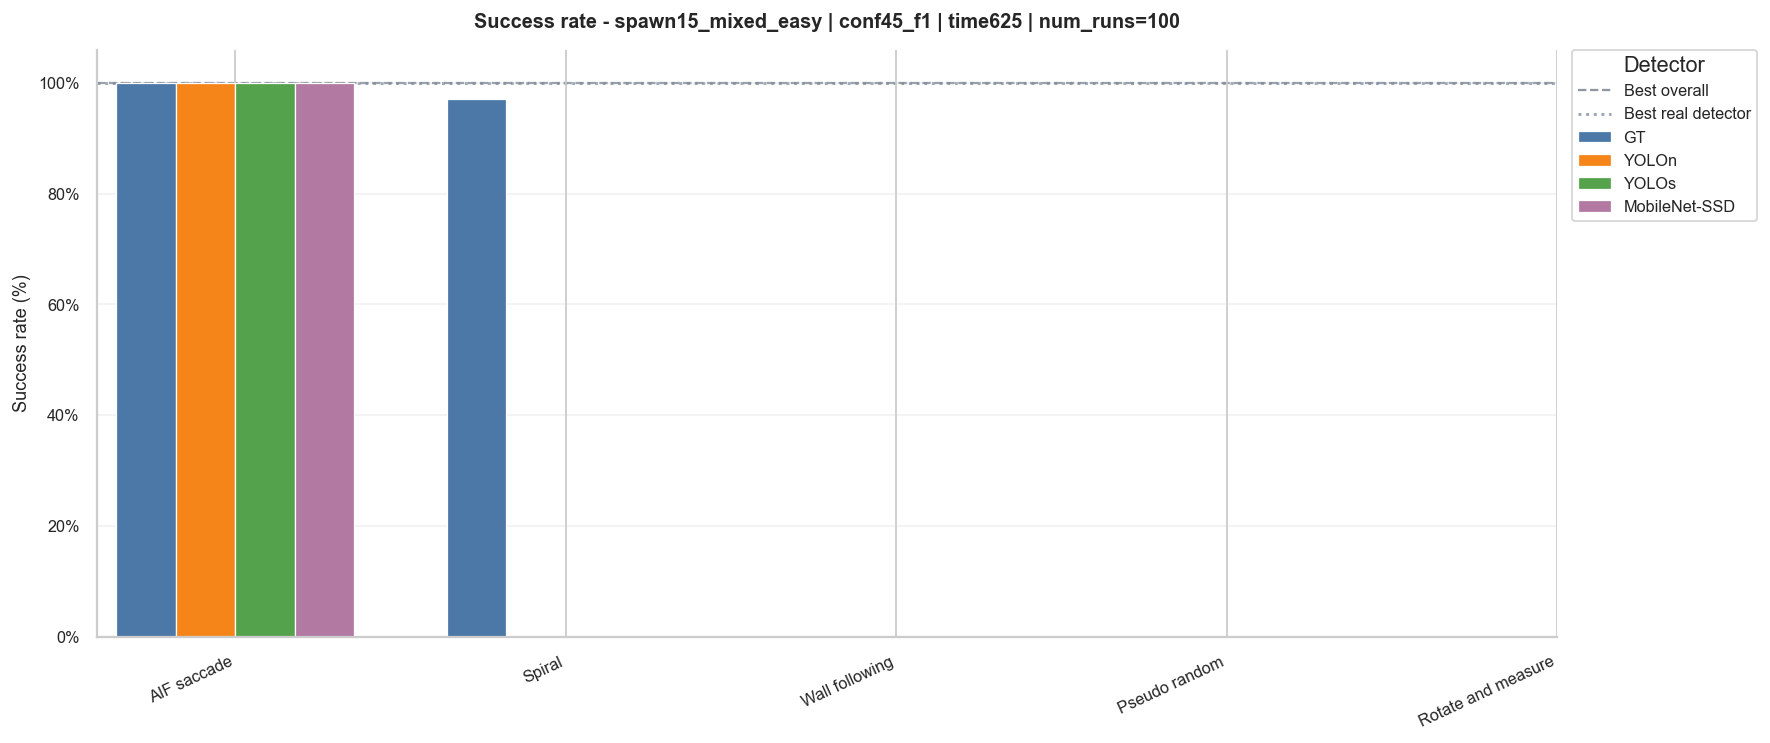

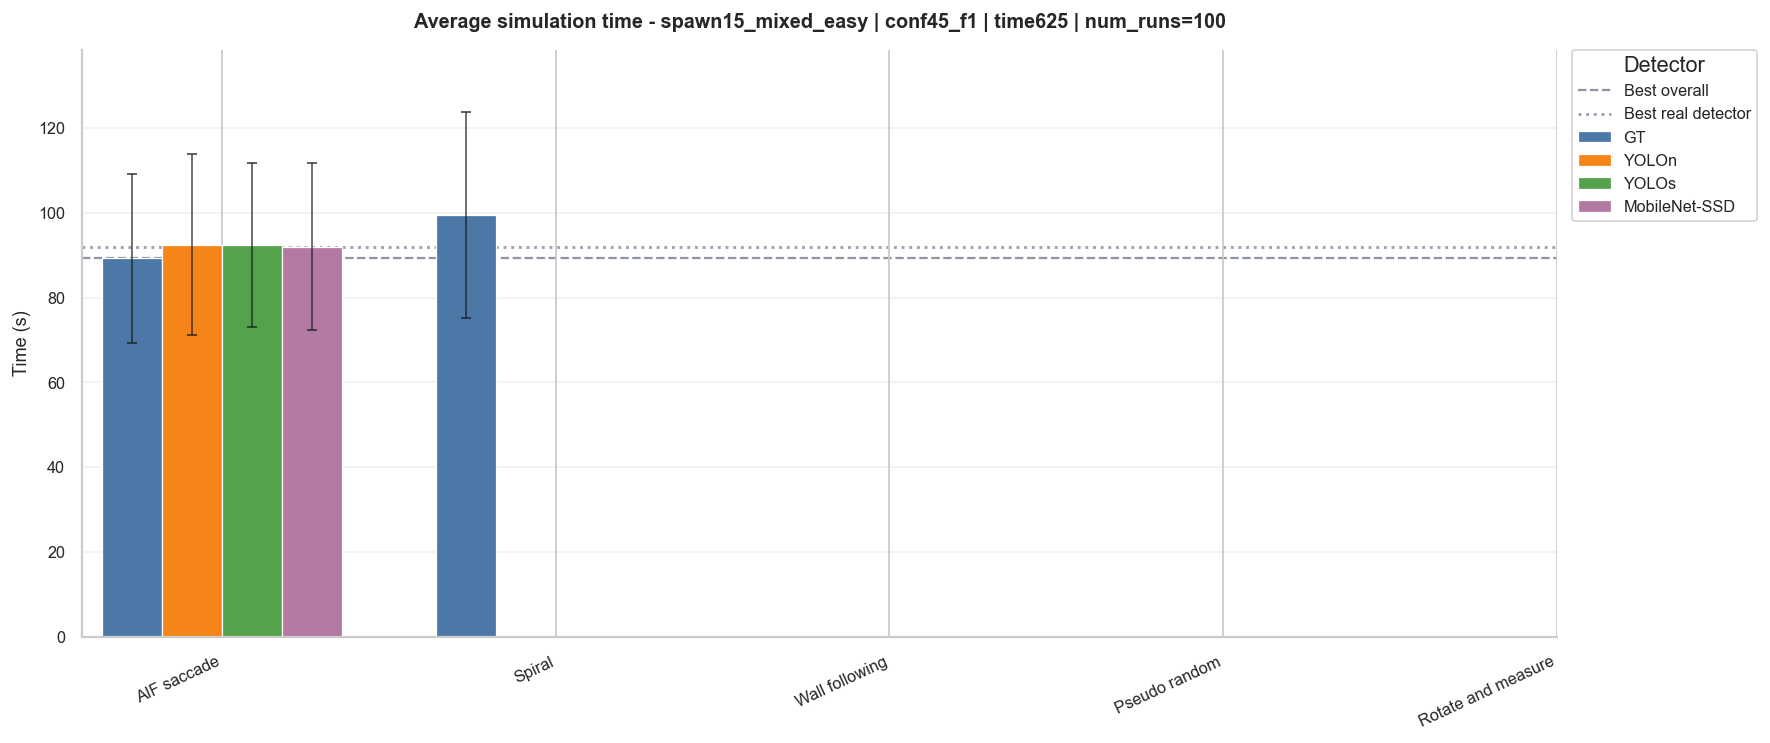

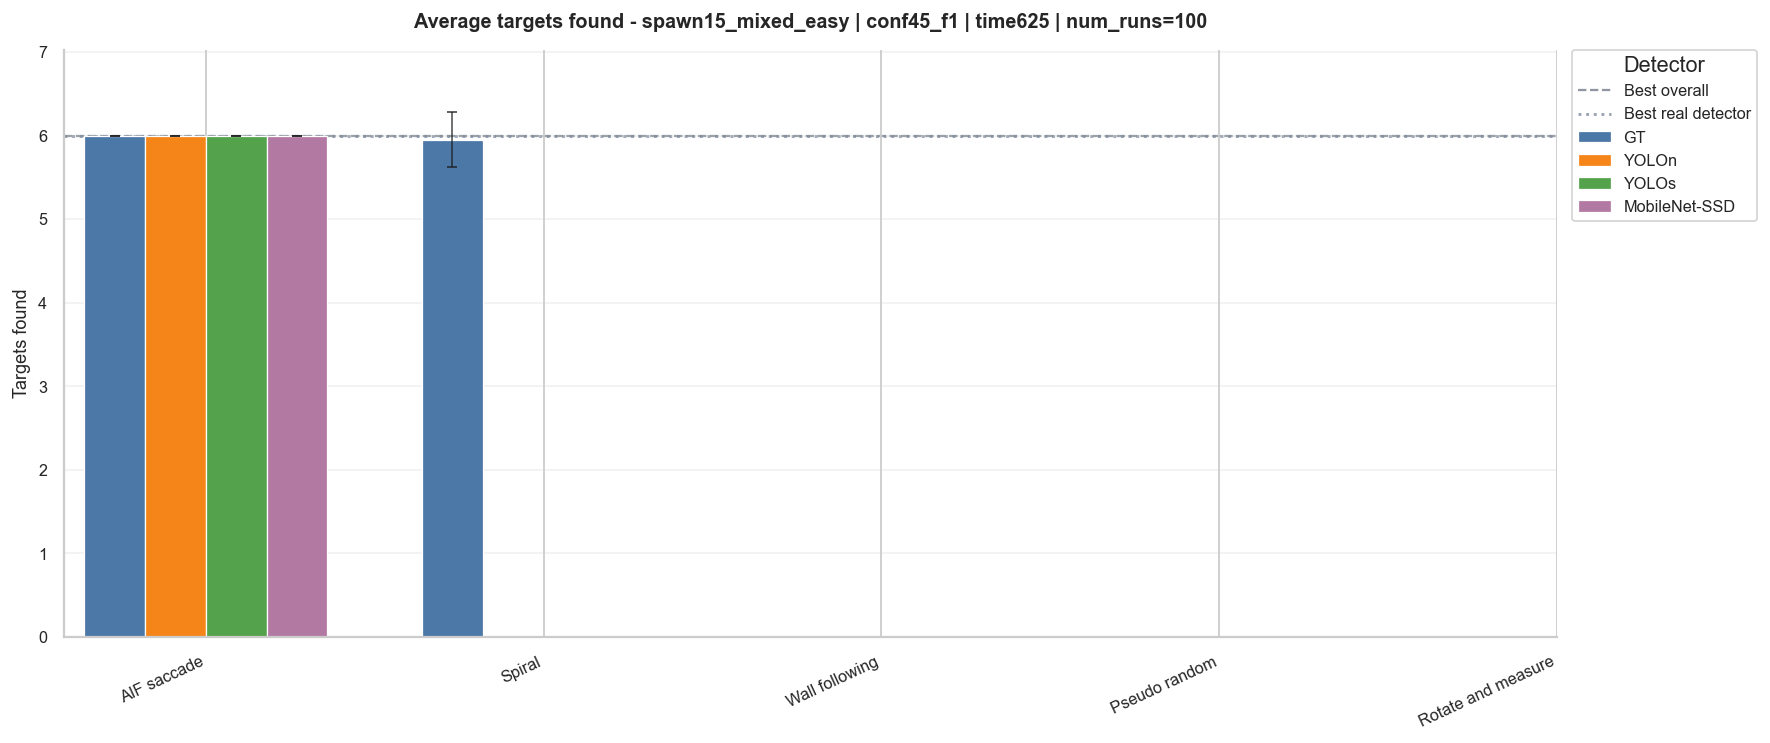

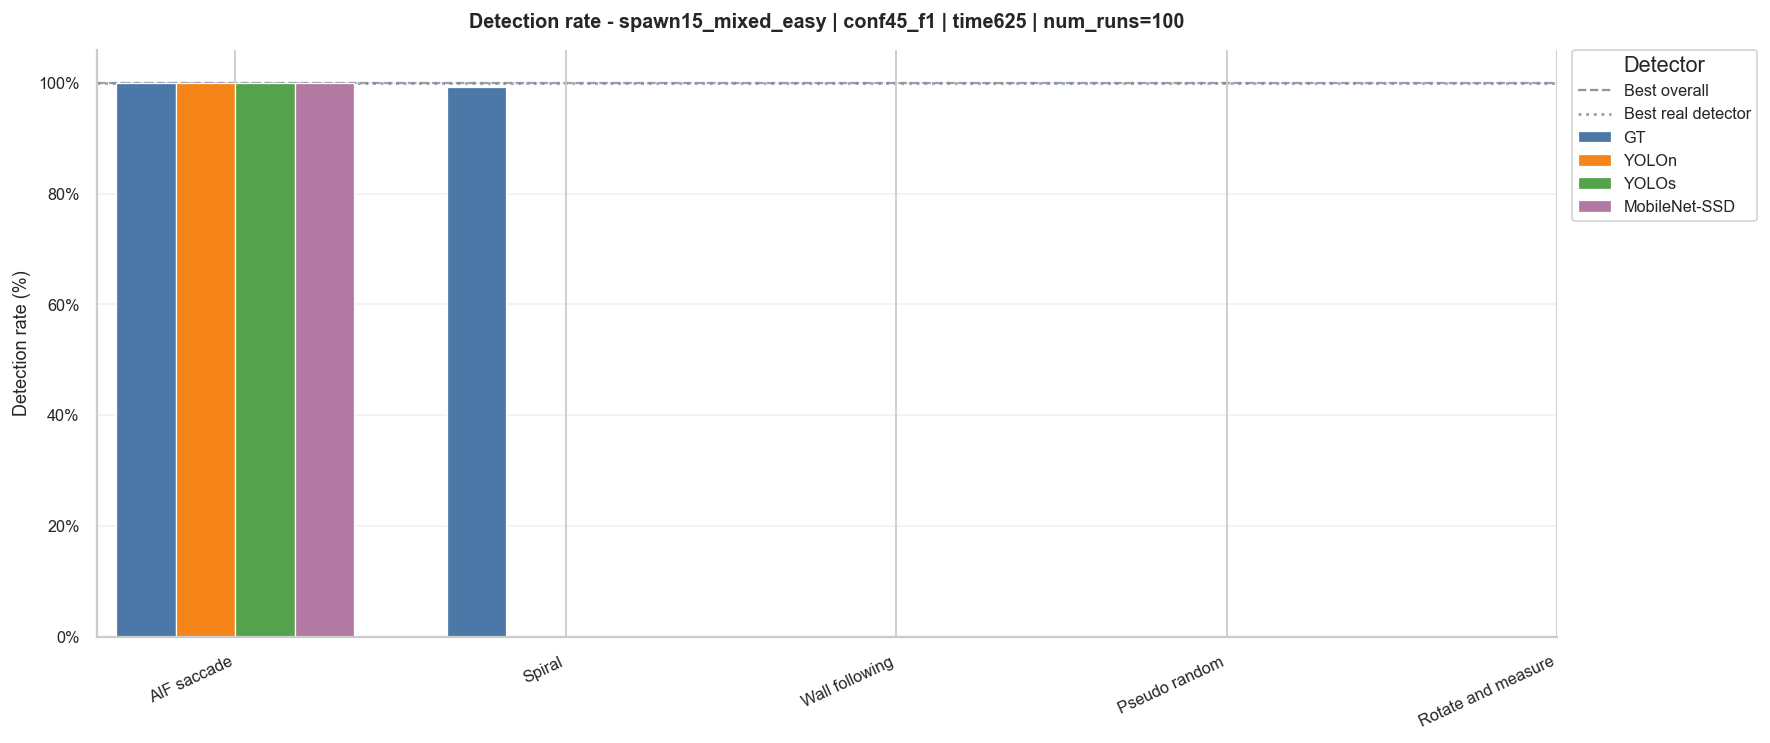

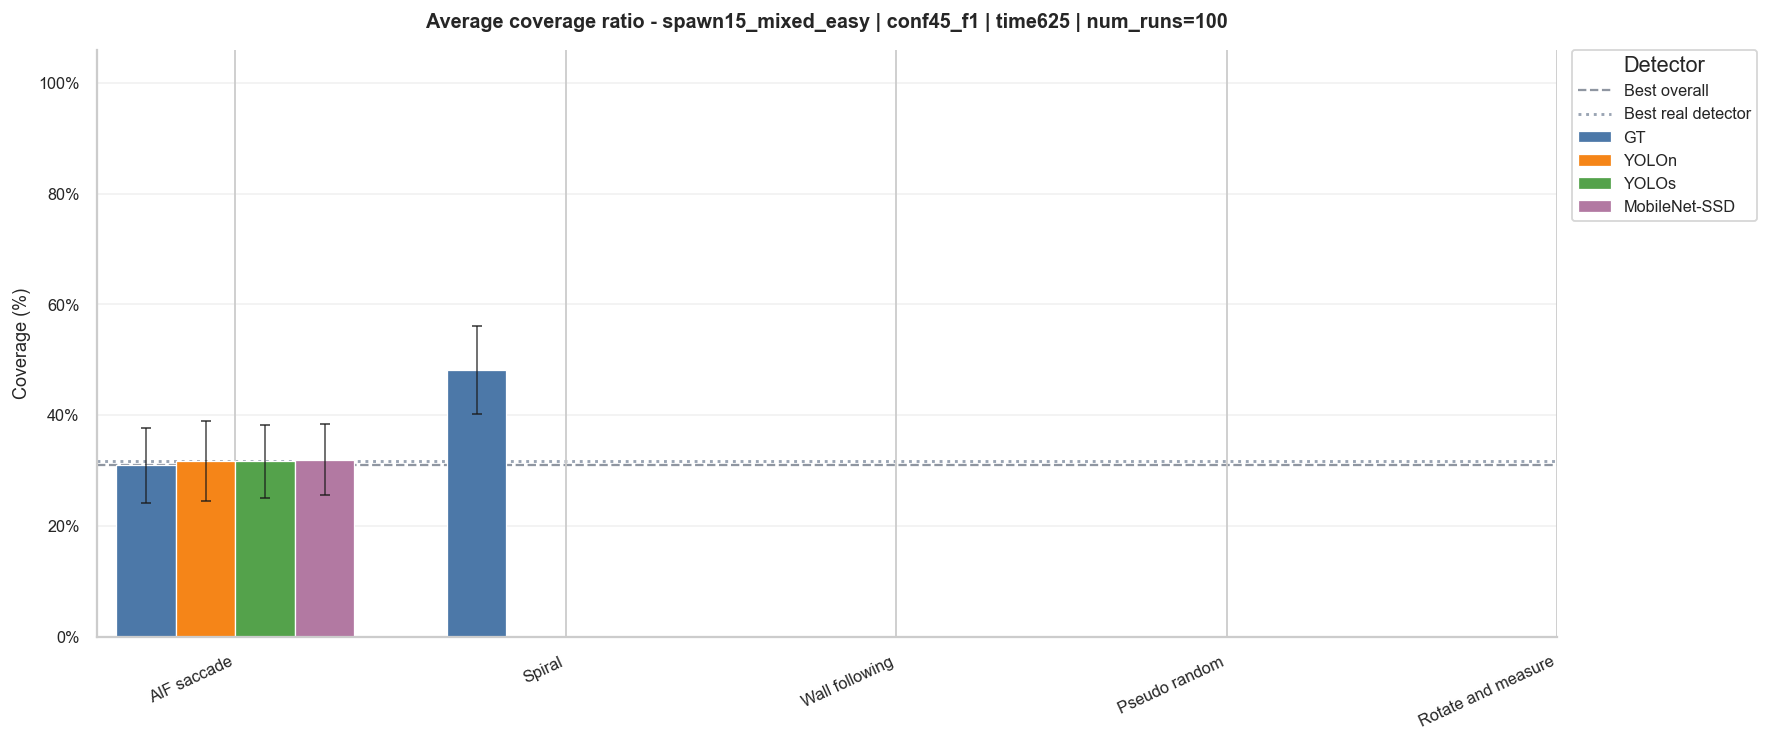

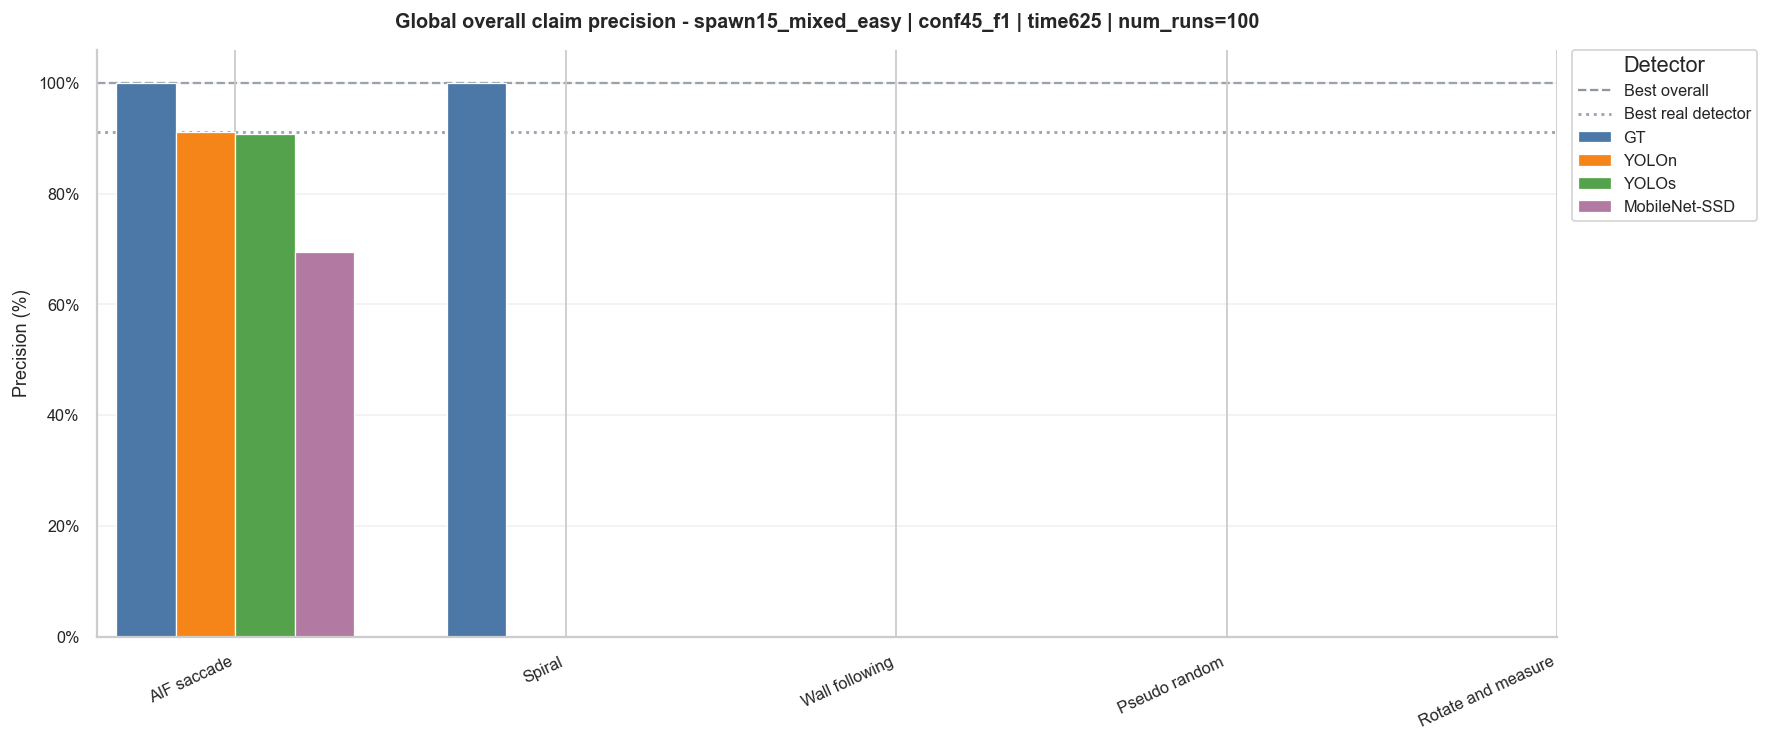

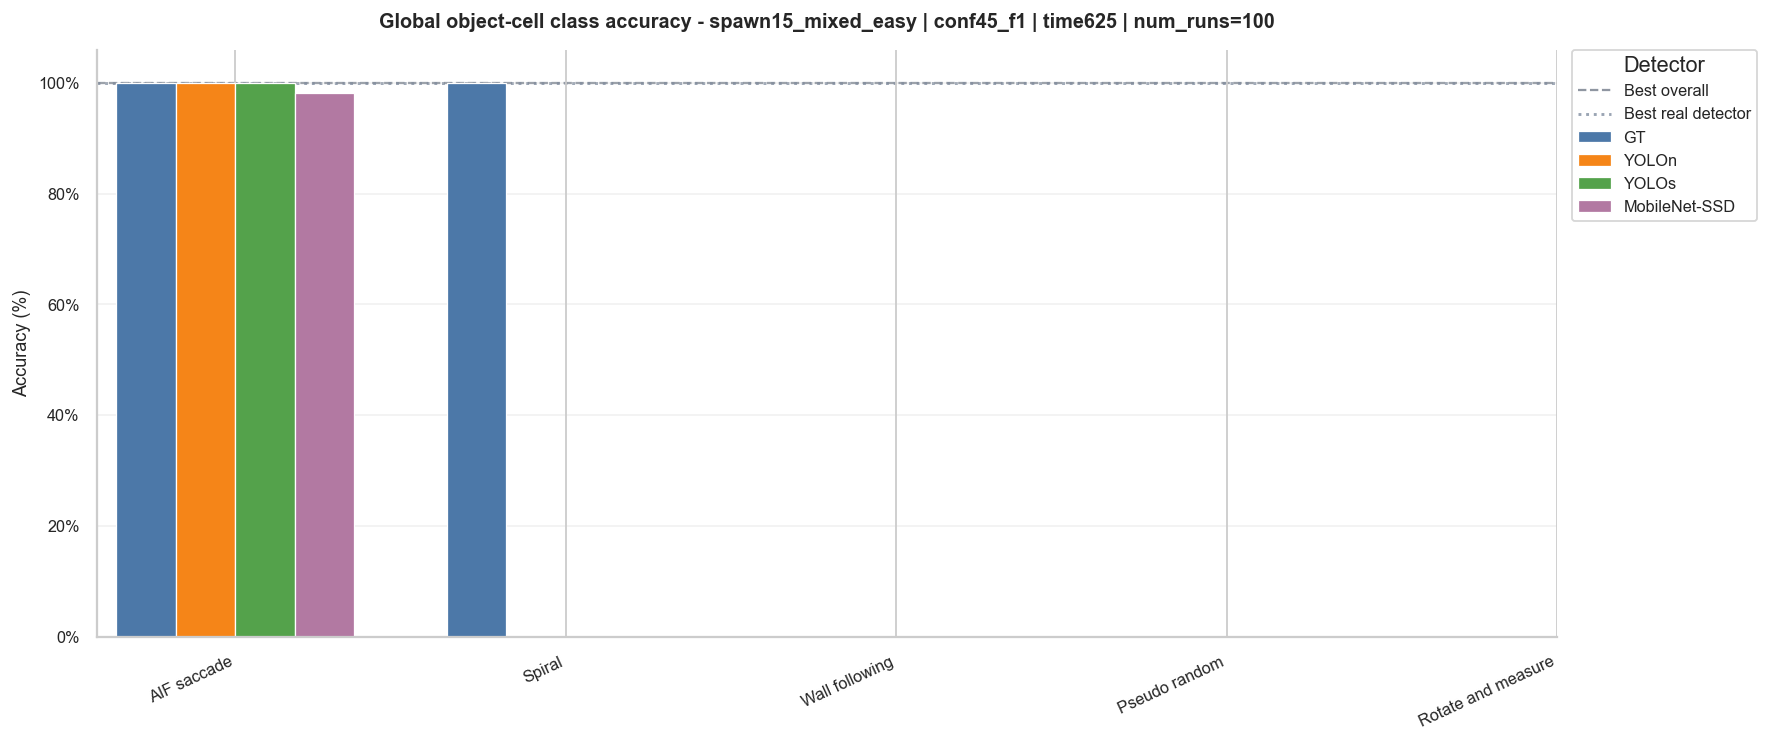

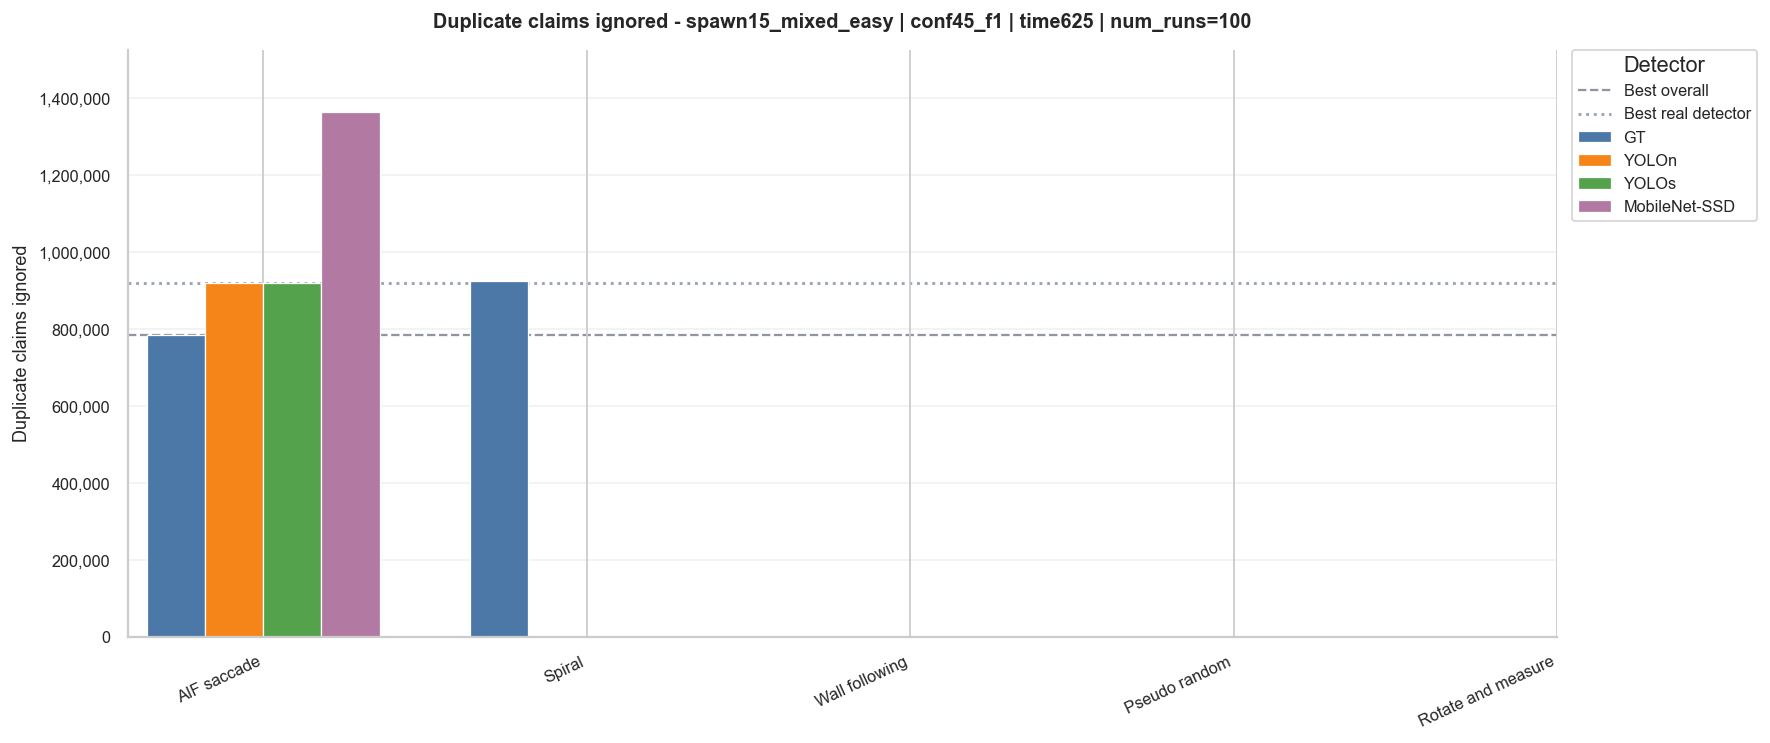

### spawn15_mixed_easy | conf45_f3 | time625 | num_runs=100

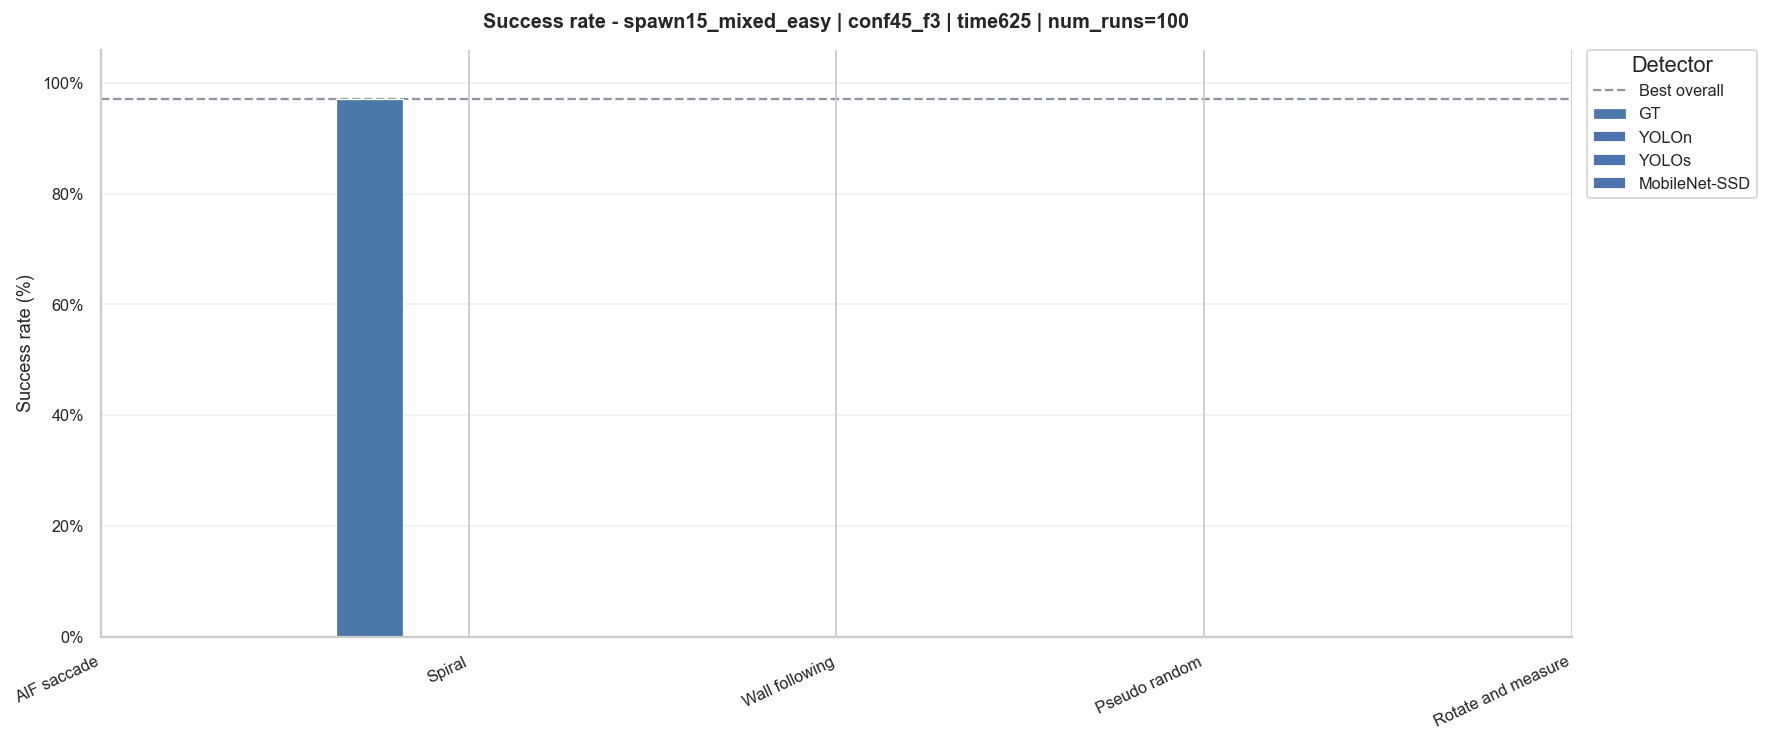

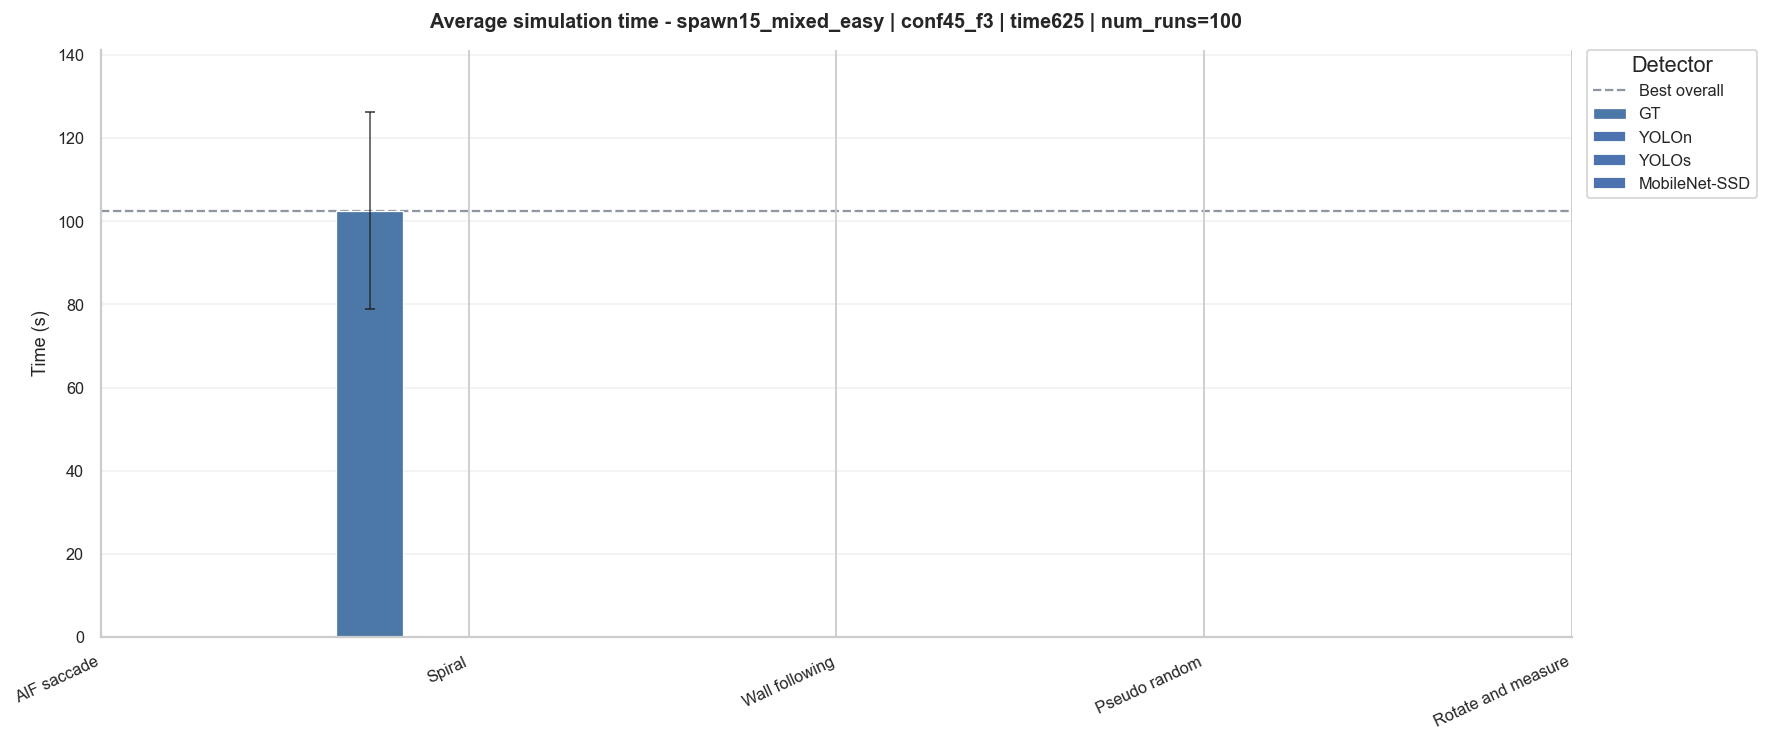

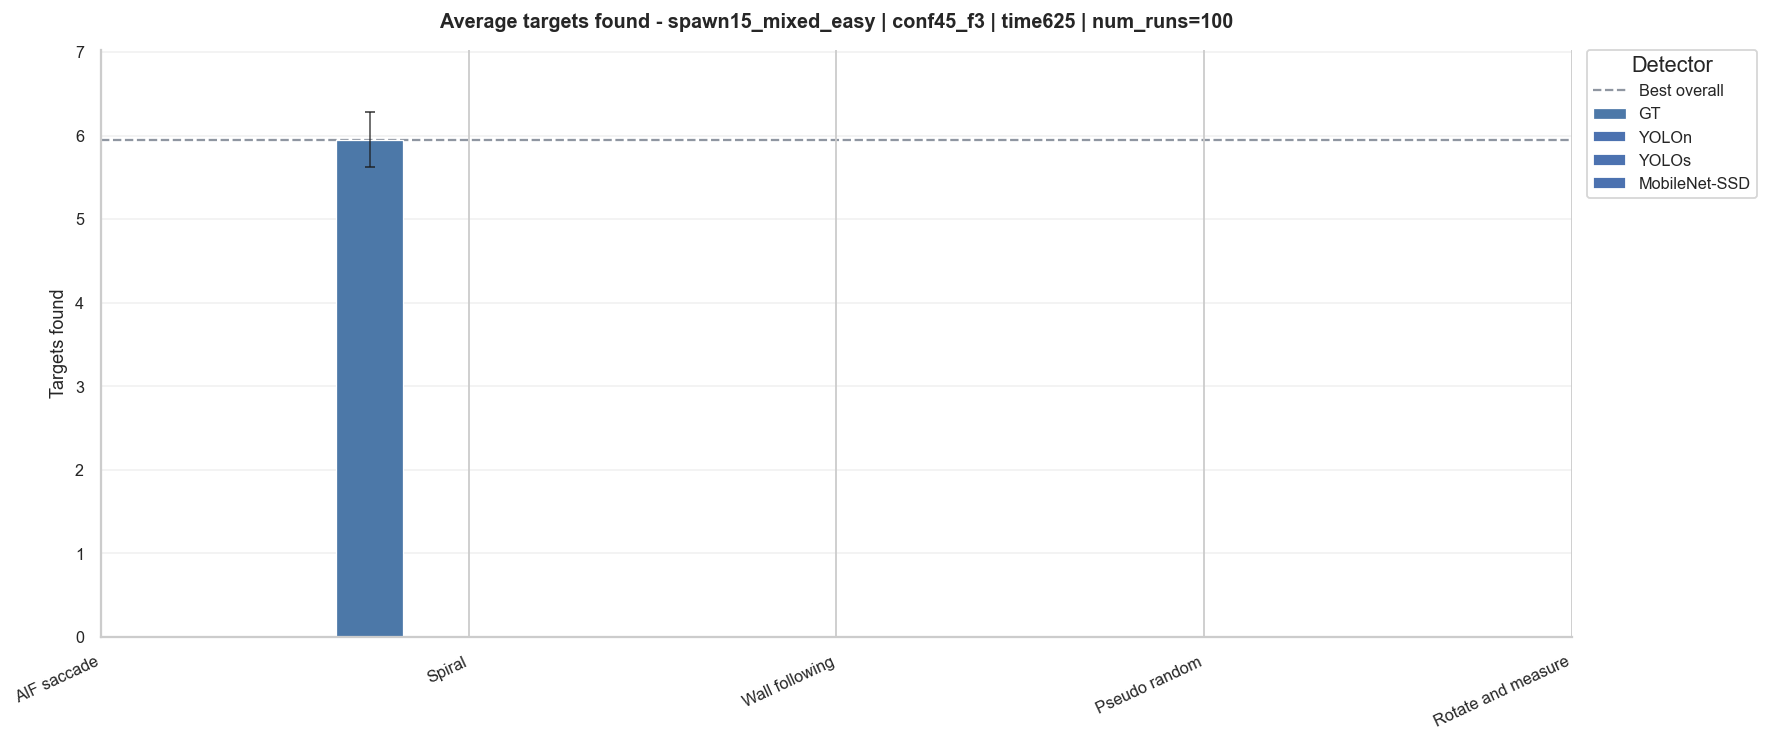

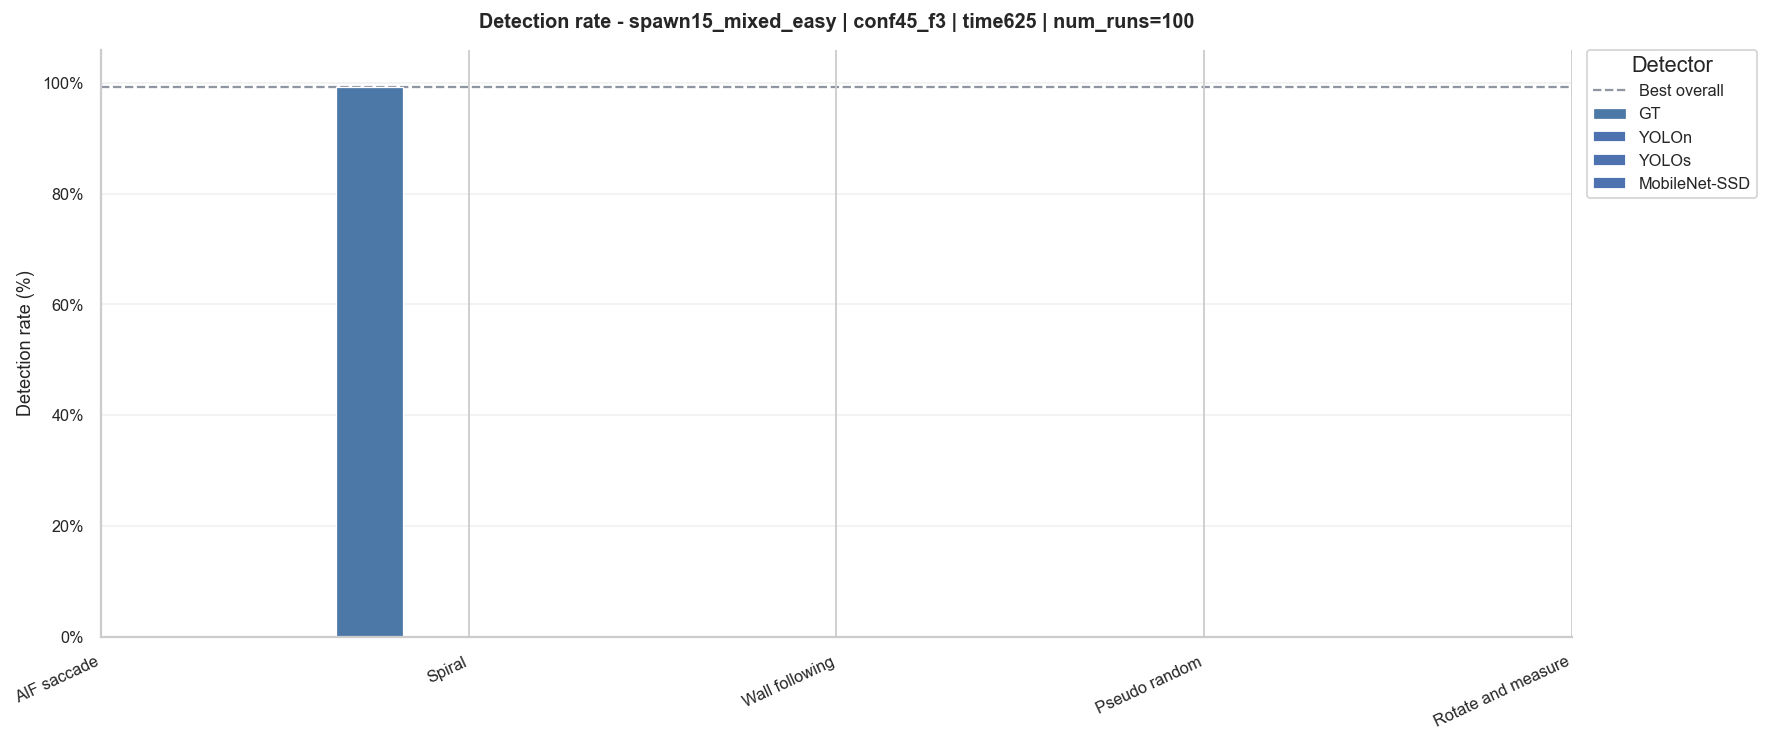

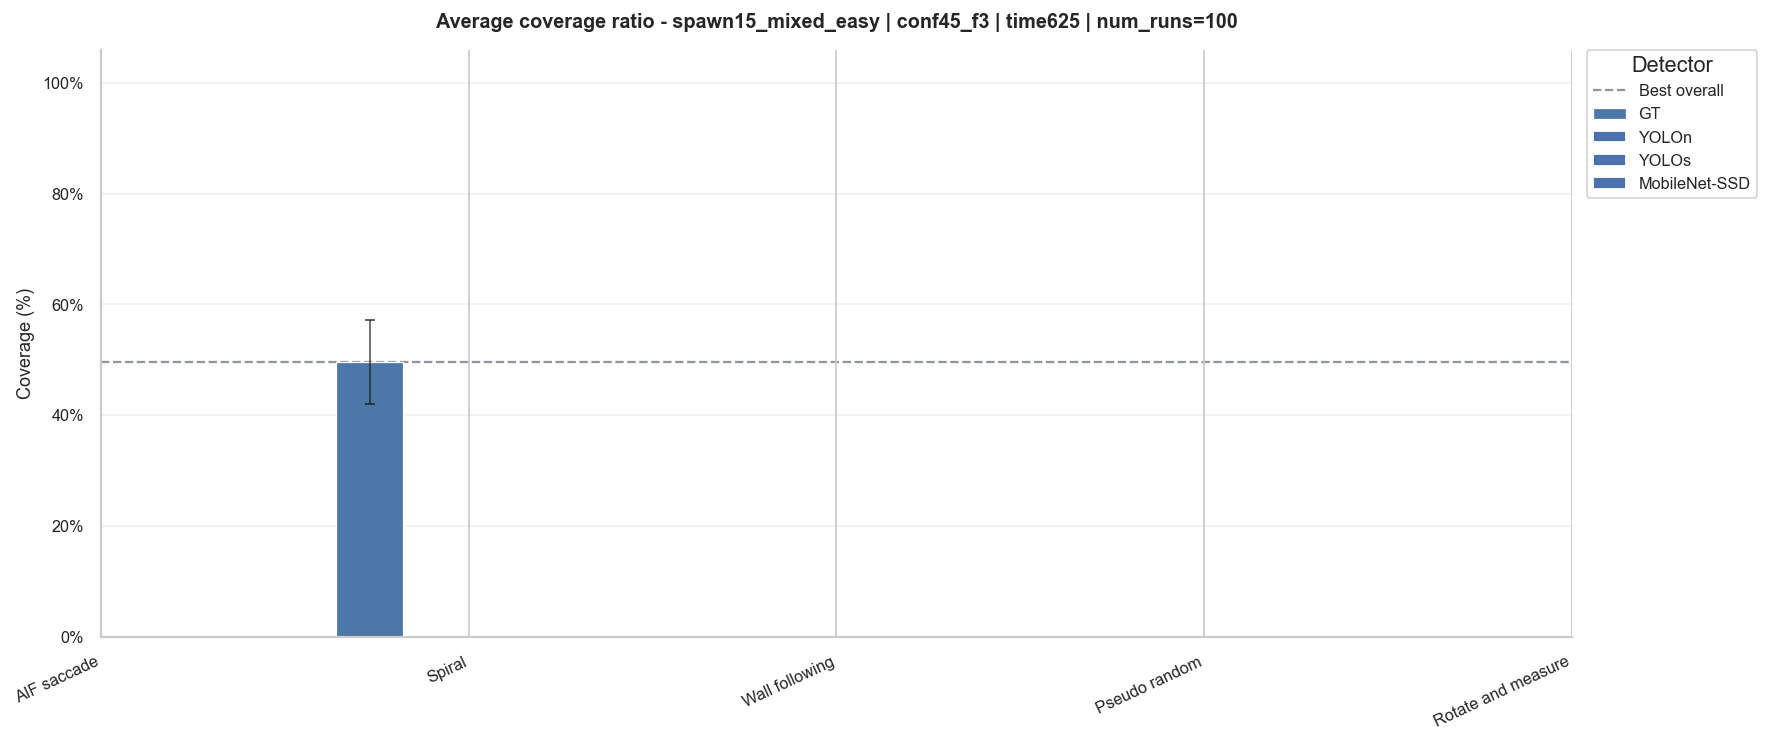

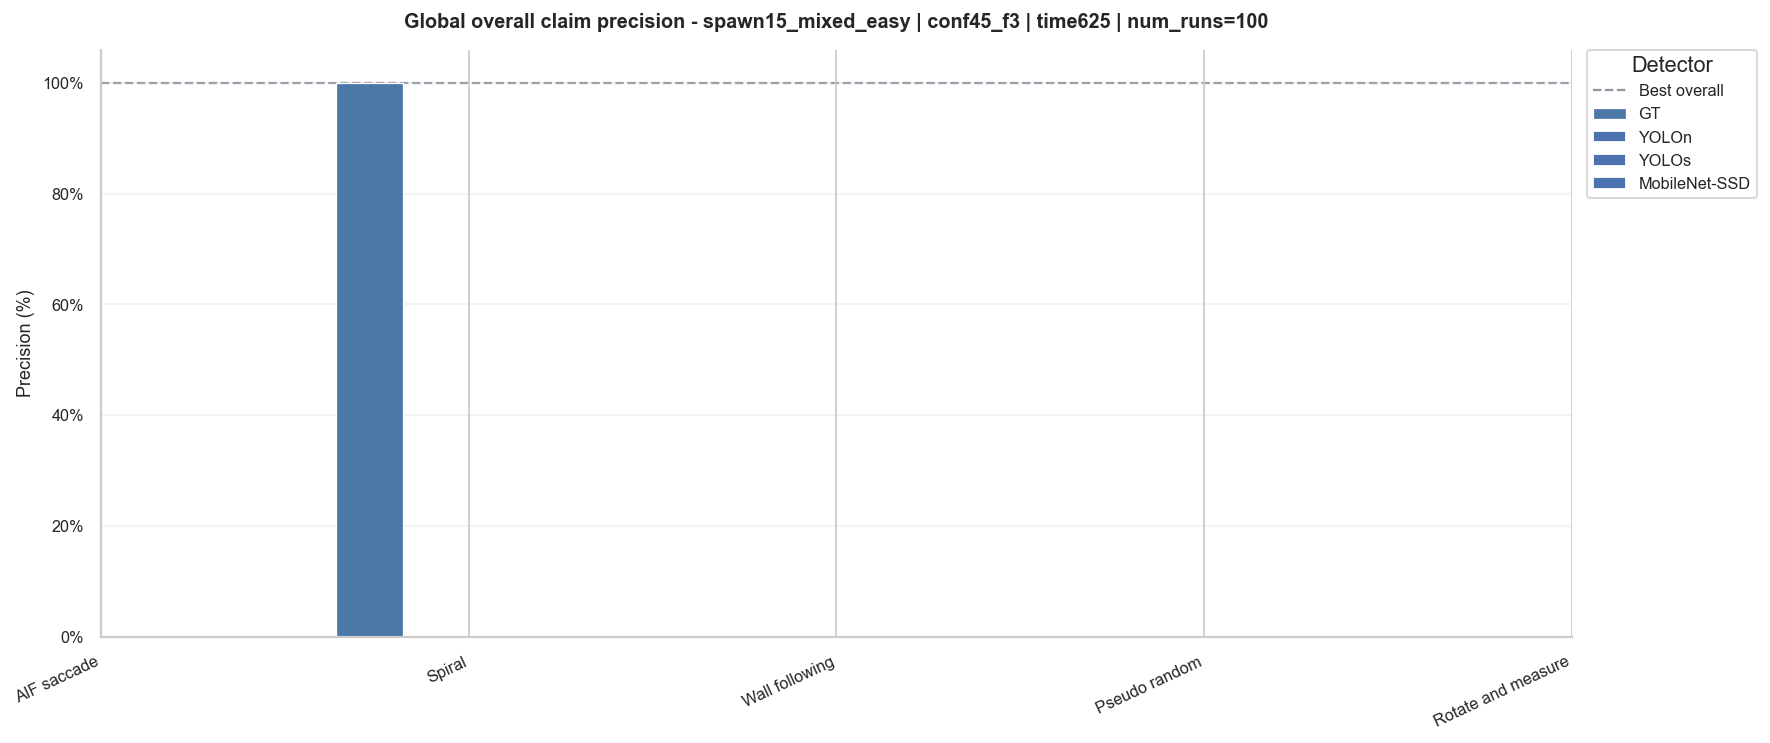

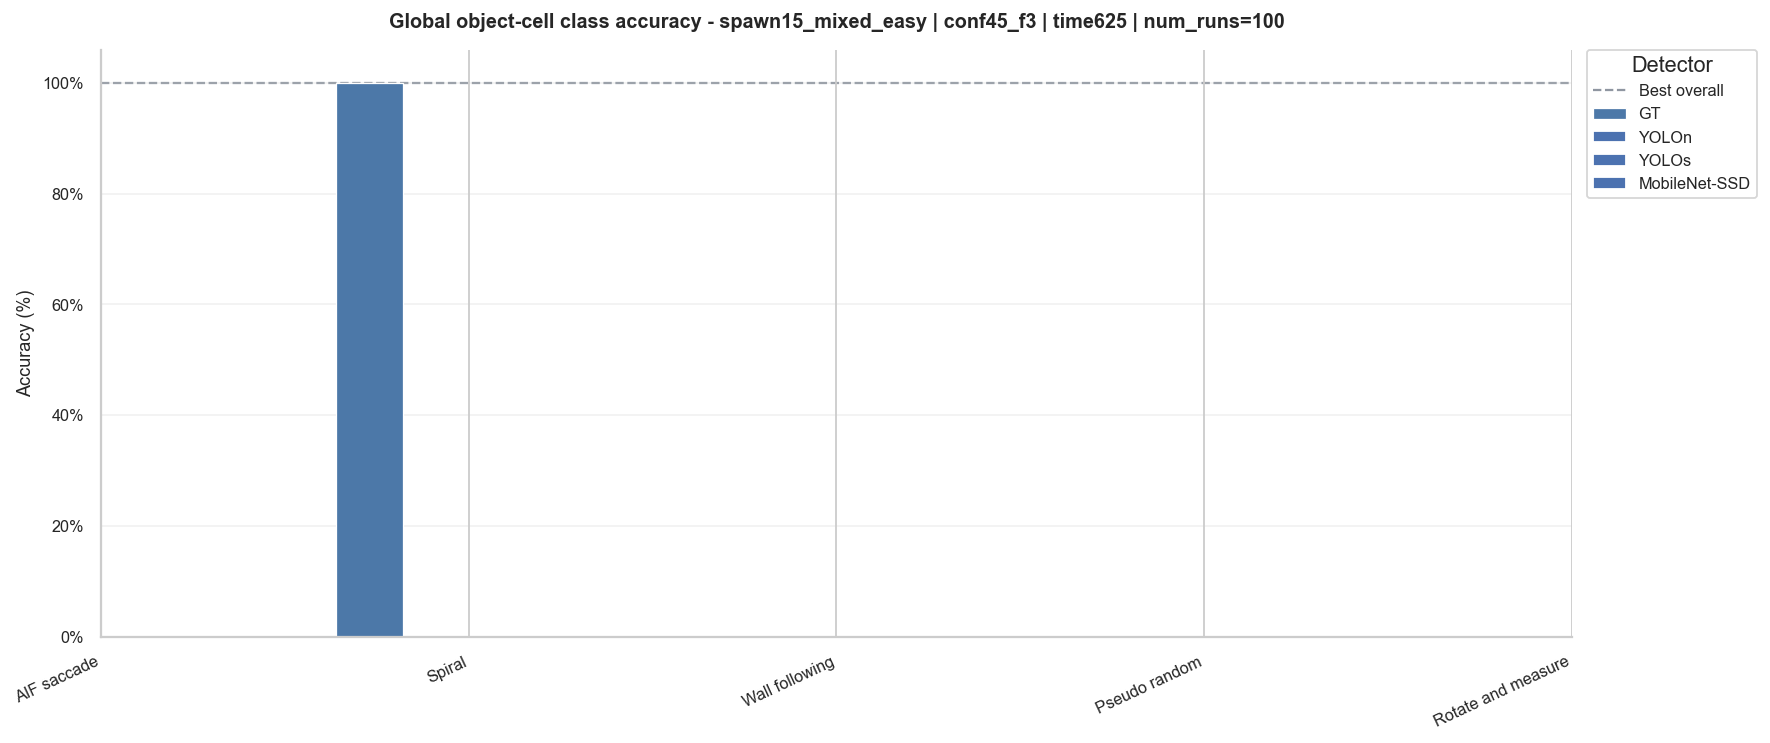

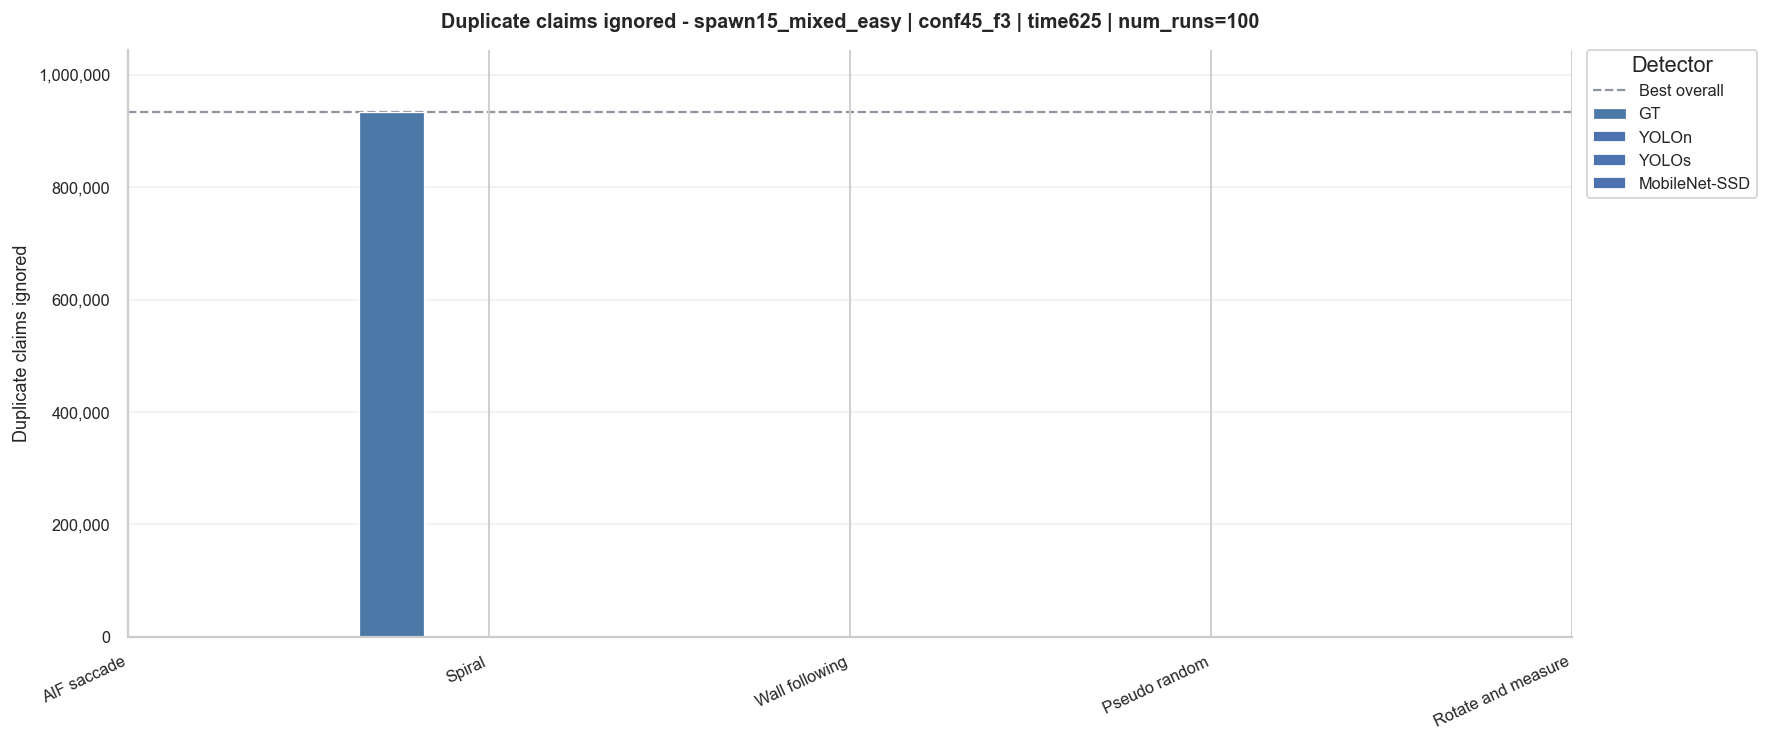

In [7]:
METRIC_SPECS = [
    {"value": "success_rate", "std": None, "title": "Success rate", "ylabel": "Success rate (%)", "scale": 100.0, "percent_axis": True, "lower_is_better": False},
    {"value": "average_simulation_time_s", "std": "std_simulation_time_s", "title": "Average simulation time", "ylabel": "Time (s)", "scale": 1.0, "percent_axis": False, "lower_is_better": True},
    {"value": "average_found_count", "std": "std_found_count", "title": "Average targets found", "ylabel": "Targets found", "scale": 1.0, "percent_axis": False, "lower_is_better": False},
    {"value": "detection_rate_percent", "std": None, "title": "Detection rate", "ylabel": "Detection rate (%)", "scale": 1.0, "percent_axis": True, "lower_is_better": False},
    {"value": "average_coverage_ratio", "std": "std_coverage_ratio", "title": "Average coverage ratio", "ylabel": "Coverage (%)", "scale": 100.0, "percent_axis": True, "lower_is_better": True},
    {"value": "global_overall_claim_precision", "std": None, "title": "Global overall claim precision", "ylabel": "Precision (%)", "scale": 100.0, "percent_axis": True, "lower_is_better": False},
    {"value": "global_object_cell_class_accuracy", "std": None, "title": "Global object-cell class accuracy", "ylabel": "Accuracy (%)", "scale": 100.0, "percent_axis": True, "lower_is_better": False},
    {"value": "total_duplicate_claims_ignored", "std": None, "title": "Duplicate claims ignored", "ylabel": "Duplicate claims ignored", "scale": 1.0, "percent_axis": False, "lower_is_better": True},
]


def ordered_present(values: list[str], preferred_order: list[str]) -> list[str]:
    unique = sorted(set(values))
    return [value for value in preferred_order if value in unique] + [value for value in unique if value not in preferred_order]


def records_by_key(records: list[dict[str, Any]], key_fields: list[str]) -> dict[tuple[Any, ...], list[dict[str, Any]]]:
    grouped: dict[tuple[Any, ...], list[dict[str, Any]]] = defaultdict(list)
    for row in records:
        grouped[tuple(row.get(field) for field in key_fields)].append(row)
    return dict(sorted(grouped.items(), key=lambda item: item[0]))


def best_metric_value(group: list[dict[str, Any]], metric: dict[str, Any], real_detectors_only: bool = False) -> float:
    values = []
    for row in group:
        if real_detectors_only and row.get("detector_label") == "GT":
            continue
        value = as_float(row.get(metric["value"]))
        if not math.isnan(value):
            values.append(value * metric["scale"])
    if not values:
        return math.nan
    return min(values) if metric.get("lower_is_better") else max(values)


def plot_grouped_metric(ax: plt.Axes, group: list[dict[str, Any]], metric: dict[str, Any]) -> None:
    extra_policies = ordered_present([str(row.get("policy_label")) for row in group], POLICY_ORDER)
    extra_detectors = ordered_present([str(row.get("detector_label")) for row in group], DETECTOR_ORDER)
    policies = POLICY_ORDER + [value for value in extra_policies if value not in POLICY_ORDER]
    detectors = DETECTOR_ORDER + [value for value in extra_detectors if value not in DETECTOR_ORDER]

    lookup = {(row.get("policy_label"), row.get("detector_label")): row for row in group}
    x = np.arange(len(policies))
    bar_width = min(0.18, 0.82 / max(len(detectors), 1))
    offsets = (np.arange(len(detectors)) - (len(detectors) - 1) / 2) * bar_width
    plotted_values: list[float] = []

    for idx, detector in enumerate(detectors):
        heights = []
        errors = []
        for policy in policies:
            row = lookup.get((policy, detector))
            value = as_float(row.get(metric["value"])) if row else math.nan
            height = value * metric["scale"] if not math.isnan(value) else math.nan
            heights.append(height)

            if metric["std"] and row:
                err = as_float(row.get(metric["std"]))
                errors.append(0.0 if math.isnan(err) else err * metric["scale"])
            else:
                errors.append(0.0)

            if not math.isnan(height):
                plotted_values.append(height + errors[-1])

        if all(math.isnan(height) for height in heights):
            ax.bar([], [], label=detector, color=DETECTOR_COLORS.get(detector))
            continue

        yerr = errors if metric["std"] else None
        ax.bar(
            x + offsets[idx],
            heights,
            width=bar_width,
            label=detector,
            color=DETECTOR_COLORS.get(detector),
            edgecolor="white",
            linewidth=0.7,
            yerr=yerr,
            capsize=2.5 if yerr is not None else 0,
            error_kw={"elinewidth": 0.9, "alpha": 0.75},
        )

    best_overall = best_metric_value(group, metric, real_detectors_only=False)
    best_real = best_metric_value(group, metric, real_detectors_only=True)
    if not math.isnan(best_overall):
        ax.axhline(
            best_overall,
            color="#334155",
            linestyle="--",
            linewidth=1.25,
            alpha=0.55,
            label="Best overall",
            zorder=0,
        )
    if not math.isnan(best_real):
        ax.axhline(
            best_real,
            color="#64748B",
            linestyle=":",
            linewidth=1.6,
            alpha=0.65,
            label="Best real detector",
            zorder=0,
        )

    ax.set_title(metric["title"])
    ax.set_ylabel(metric["ylabel"])
    ax.set_xticks(x)
    ax.set_xticklabels(policies, rotation=25, ha="right")
    ax.grid(axis="y", alpha=0.25)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    if metric["percent_axis"]:
        ax.yaxis.set_major_formatter(mtick.PercentFormatter(xmax=100))
        ax.set_ylim(0, max(100, max(plotted_values, default=0)) * 1.06)
    else:
        top = max(plotted_values, default=1)
        ax.set_ylim(0, top * 1.12 if top > 0 else 1)
        if top >= 1000:
            ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("{x:,.0f}"))


def metric_key(text: str) -> str:
    return "".join(ch for ch in str(text).lower() if ch.isalnum())


def metric_spec_by_name(metric_name: str) -> dict[str, Any]:
    aliases = {
        metric_key(spec["title"]): spec for spec in METRIC_SPECS
    }
    aliases.update({metric_key(spec["value"]): spec for spec in METRIC_SPECS})
    key = metric_key(metric_name)
    if key not in aliases:
        available = ", ".join(spec["title"] for spec in METRIC_SPECS)
        raise ValueError(f"Unknown metric '{metric_name}'. Available metrics: {available}")
    return aliases[key]


def safe_file_label(value: Any) -> str:
    text = str(value).strip().replace("%", "pct")
    return "".join(ch if ch.isalnum() or ch in {"-", "_"} else "_" for ch in text).strip("_")


def plot_metric_figure(group: list[dict[str, Any]], group_key: tuple[Any, ...], metric: dict[str, Any], figsize: tuple[float, float] = (13.5, 5.6)) -> plt.Figure:
    experiment_setup, claim_thresholds, detector_limitations, num_runs = group_key
    group_title = f"{experiment_setup} | {claim_thresholds} | {detector_limitations} | num_runs={num_runs}"

    fig, ax = plt.subplots(figsize=figsize, constrained_layout=True)
    plot_grouped_metric(ax, group, metric)
    handles, labels = ax.get_legend_handles_labels()
    ax.legend(
        handles,
        labels,
        title="Detector",
        loc="upper left",
        bbox_to_anchor=(1.01, 1.0),
        borderaxespad=0.0,
        frameon=True,
    )
    ax.set_title(wrap_title(f"{metric['title']} - {group_title}", width=105), pad=12)
    return fig


def plot_all_metric_figures(records: list[dict[str, Any]], save: bool = SAVE_FIGURES) -> None:
    if not records:
        display(Markdown("No reports loaded; no plots generated."))
        return

    group_fields = ["experiment_setup", "claim_thresholds", "detector_limitations_label", "num_runs"]
    for group_key, group in records_by_key(records, group_fields).items():
        display(Markdown(f"### {group_key[0]} | {group_key[1]} | {group_key[2]} | num_runs={group_key[3]}"))
        for metric in METRIC_SPECS:
            fig = plot_metric_figure(group, group_key, metric)
            if save:
                FIGURE_DIR.mkdir(parents=True, exist_ok=True)
                group_name = "__".join(safe_file_label(part) for part in group_key)
                metric_name = safe_file_label(metric["title"])
                fig.savefig(FIGURE_DIR / f"results__{group_name}__{metric_name}.png", dpi=220, bbox_inches="tight")
            if "agg" in plt.get_backend().lower():
                plt.close(fig)
            else:
                plt.show()


plot_all_metric_figures(records)

## Optional Exports

In [8]:
EXPORT_TABLES = False
EXPORT_DIR = Path("webots/controllers/crazyflie_AIF/utils/results_comp_tables")


def write_csv(path: Path, rows: list[dict[str, Any]]) -> None:
    if not rows:
        return
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=list(rows[0].keys()))
        writer.writeheader()
        writer.writerows(rows)


if EXPORT_TABLES:
    EXPORT_DIR.mkdir(parents=True, exist_ok=True)
    write_csv(EXPORT_DIR / "overall_results.csv", overall_table)
    write_csv(EXPORT_DIR / "target_distance_results.csv", target_distance_table)
    display(Markdown(f"Exported tables to `{EXPORT_DIR}`."))

## Single Figure Export

Edit this cell to print and save one selected metric for one selected experiment group. `SINGLE_METRIC` can be either the metric title shown in the plots or the raw metric key.

Saved single figure to `results_comp_single_figures/spawn15_mixed_easy__conf45_f3__time625__100__Average_coverage_ratio.png`.

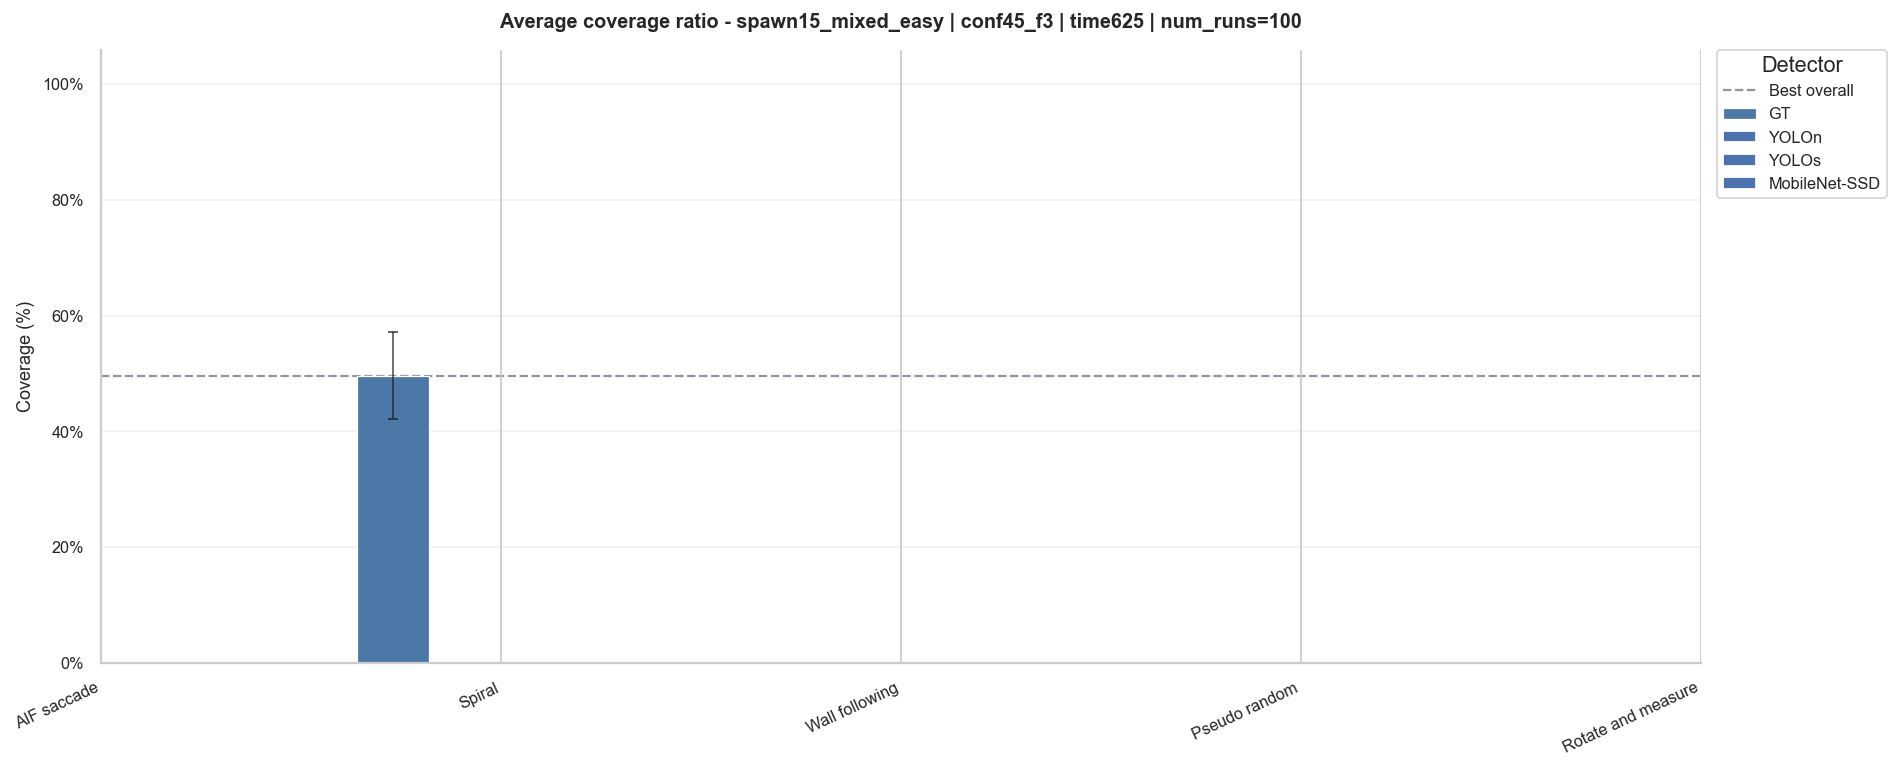

In [9]:
SINGLE_EXPERIMENT_SETUP = "spawn15_mixed_easy"
SINGLE_CLAIM_THRESHOLDS = "conf45_f3"
SINGLE_DETECTOR_LIMITATIONS = "time625"
SINGLE_NUM_RUNS = 100
SINGLE_METRIC = "Average coverage ratio"

SINGLE_FIGURE_DIR = Path("results_comp_single_figures")
SINGLE_FIGURE_DPI = 300
SAVE_SINGLE_FIGURE = True


single_group_key = (
    SINGLE_EXPERIMENT_SETUP,
    SINGLE_CLAIM_THRESHOLDS,
    SINGLE_DETECTOR_LIMITATIONS,
    SINGLE_NUM_RUNS,
)
single_groups = records_by_key(records, ["experiment_setup", "claim_thresholds", "detector_limitations_label", "num_runs"])
single_group = single_groups.get(single_group_key, [])

if not single_group:
    available_groups = "\n".join(
        f"- {key[0]} | {key[1]} | {key[2]} | num_runs={key[3]}"
        for key in single_groups
    )
    display(Markdown(f"**Selected group not found.**\n\nAvailable groups:\n{available_groups}"))
else:
    single_metric = metric_spec_by_name(SINGLE_METRIC)
    single_fig = plot_metric_figure(single_group, single_group_key, single_metric, figsize=(14.5, 5.8))
    if SAVE_SINGLE_FIGURE:
        SINGLE_FIGURE_DIR.mkdir(parents=True, exist_ok=True)
        group_name = "__".join(safe_file_label(part) for part in single_group_key)
        metric_name = safe_file_label(single_metric["title"])
        output_path = SINGLE_FIGURE_DIR / f"{group_name}__{metric_name}.png"
        single_fig.savefig(output_path, dpi=SINGLE_FIGURE_DPI, bbox_inches="tight")
        display(Markdown(f"Saved single figure to `{output_path}`."))
    if "agg" in plt.get_backend().lower():
        plt.close(single_fig)
    else:
        plt.show()
